# Equipment System Effectiveness (SE): model, test and 30-day forecast

**Goal:** predict the daily System Effectiveness of 12 equipments (Pump 1-8, Gen A-C, Blackstart) for 16 Nov 2026 and the following 29 days (30 days in total), using data from 1 Jan to 15 Nov 2026.

**What the data looks like (found in the steps below):**
1. When nothing happens, SE **declines slowly and almost linearly** (about 1 percentage point every 7-8 days for the pumps).
2. After thorough maintenance SE **jumps up** (sometimes above 100%) and then starts declining again from the new level.
3. Equipment also has **outages**: SE drops to 0% (or to a partial value on the day it goes down or comes back). These are events, not wear, so they must not be allowed to distort the decline trend.

**Approach:** \
<br>
(1) load and clean \
(2) look at the data \
(3) separate "healthy" days from outage days \
(4) find maintenance jumps and keep only the data since the last one \
(5) fit a robust decline line to that data \
(6) decide if the equipment is in a long outage \
(7) back-test on many past periods \
(8) hold out the last 30 days as a test set and write the test CSV \
(9) refit on all data and write the 30-day forecast CSV.

**Limit:** 
- The main limit on accuracy is not the decline trend, which is already close to exact on running days (about 0.3-0.4 points of error).
- It is outages and maintenance events the model can’t see coming. So the biggest gains come from better inputs
- Better Inputs include Planned Shutdowns, fault logs, expected maintenance duration and enough history (more than One year data)
- Also, if we KNOW the planned maintenance dates, the model can add the expected jump and restart the decline from the new level
- After a maintenance event, the model starts a new segment automatically. For sometime, it has too little data to trust and borrows the equipment’s earlier slopes, so we will expect somewhat weaker forecasts in that window



## Step 1 - Settings and loading the data

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import theilslopes

CSV_PATH = "Equipments SE CSV.csv"      # change if your file lives elsewhere
HORIZON  = 30       # days to forecast
TEST_DAYS = 30      # size of the hold-out test set (last 30 days of data)

# model settings (explained where they are used, chosen in Step 7)
OFF_LEVEL = 5       # SE below this (%) counts as "offline"
DROP_FRAC = 0.9     # a day more than 10% below the running level is an outage / ramp day
JUMP      = 4       # a persistent change of >= 4 points marks a maintenance / level shift
MIN_SEG   = 14      # minimum healthy days needed to estimate a trend
OFF_RUN   = 7       # offline for this many days in a row -> assume it stays offline

raw = pd.read_csv(CSV_PATH, encoding="utf-8-sig")           # utf-8-sig strips the hidden BOM on "Date"
raw["Date"] = pd.to_datetime(raw["Date"], format="%d/%m/%Y")  # dates are day/month/year
for c in raw.columns[1:]:
    raw[c] = raw[c].str.rstrip("%").astype(float)            # "85%" -> 85.0
data = raw.set_index("Date").sort_index()
EQUIP = list(data.columns)

print("Rows:", len(data), "| from", data.index.min().date(), "to", data.index.max().date())
print("Missing dates:", len(pd.date_range(data.index.min(), data.index.max()).difference(data.index)),
      "| duplicate dates:", data.index.duplicated().sum(), "| empty cells:", int(data.isna().sum().sum()))
data.tail()

Rows: 319 | from 2026-01-01 to 2026-11-15
Missing dates: 0 | duplicate dates: 0 | empty cells: 0


,Pump 1,Pump 2,Pump 3,Pump 4,Pump 5,Pump 6,Pump 7,Pump 8,Gen A,Gen B,Gen C,Blackstart
Date,,,,,,,,,,,,
2026-11-11,83.0,64.0,70.0,72.0,0.0,83.0,83.0,83.0,0.0,0.0,79.0,0.0
2026-11-12,83.0,64.0,70.0,71.0,0.0,83.0,83.0,83.0,0.0,0.0,79.0,0.0
2026-11-13,83.0,0.0,70.0,71.0,83.0,83.0,83.0,83.0,0.0,0.0,79.0,0.0
2026-11-14,83.0,64.0,70.0,0.0,83.0,83.0,83.0,83.0,0.0,0.0,79.0,0.0
2026-11-15,83.0,64.0,70.0,71.0,83.0,83.0,83.0,83.0,0.0,0.0,79.0,0.0


## Step 2 - Look at the data

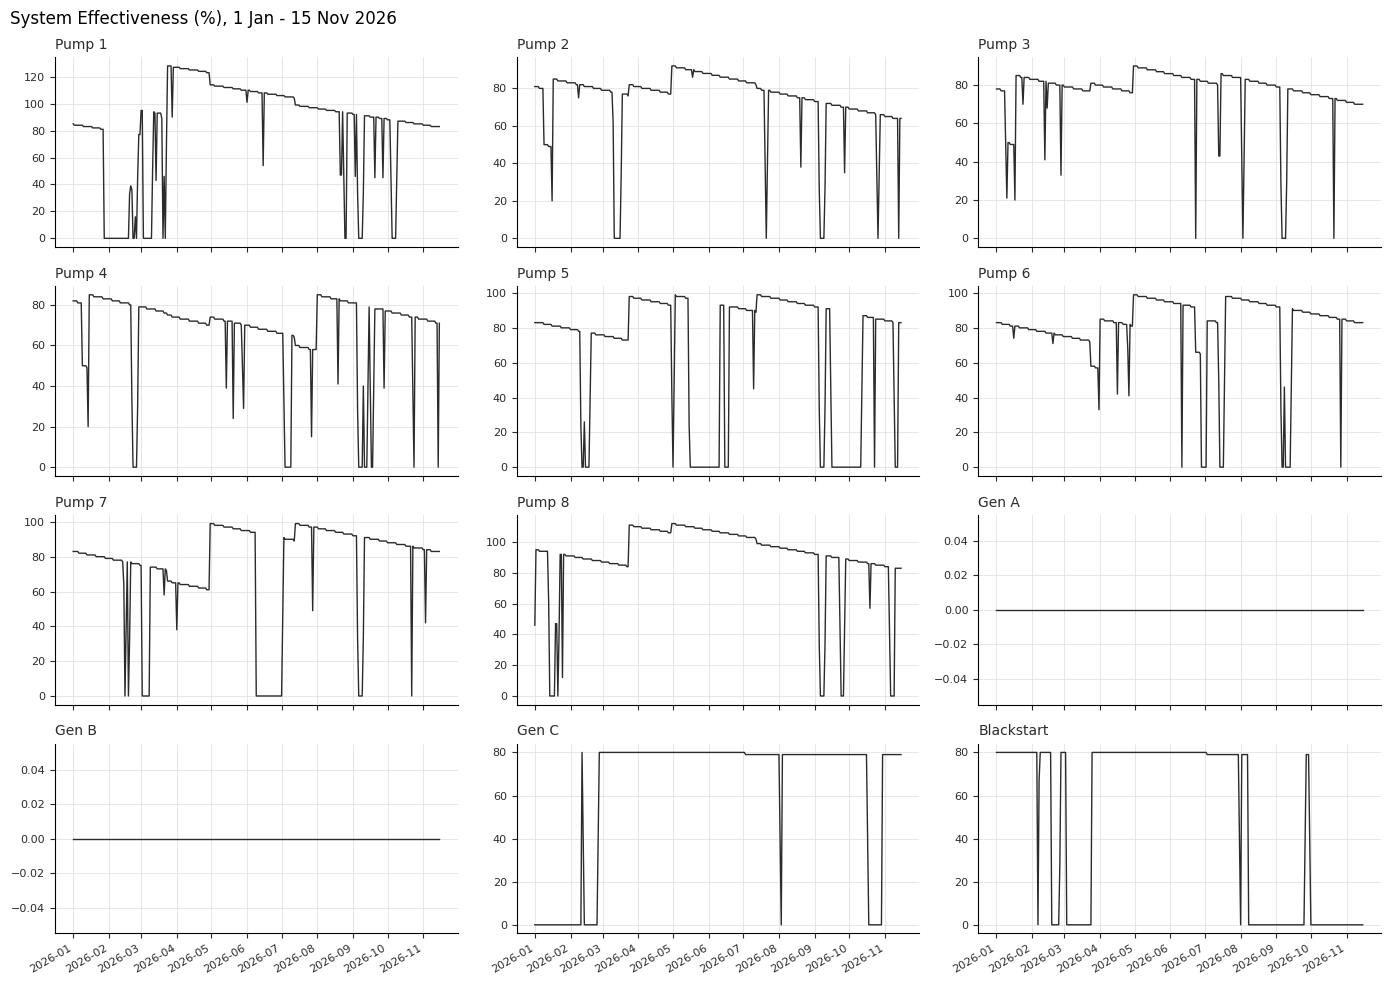

In [2]:
INK, GRID, ACCENT = "#2b2b2b", "#e3e3e3", "#2a6fdb"

def style(ax):
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.tick_params(labelsize=8, colors=INK)

fig, axes = plt.subplots(4, 3, figsize=(14, 10), sharex=True)
for ax, c in zip(axes.ravel(), EQUIP):
    ax.plot(data.index, data[c], lw=1, color=INK)
    ax.set_title(c, fontsize=10, loc="left", color=INK); style(ax)
fig.suptitle("System Effectiveness (%), 1 Jan - 15 Nov 2026", x=0.01, ha="left", fontsize=12)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

In [3]:
def longest_run(mask):
    best = cur = 0
    for x in mask:
        cur = cur + 1 if x else 0
        best = max(best, cur)
    return best

summary = pd.DataFrame({
    "days offline (<5%)": (data < OFF_LEVEL).sum(),
    "% of days offline": ((data < OFF_LEVEL).mean() * 100).round(1),
    "longest offline run (days)": [longest_run(data[c] < OFF_LEVEL) for c in EQUIP],
    "days above 100%": (data > 100).sum(),
    "latest value": data.iloc[-1],
})
summary

,days offline (<5%),% of days offline,longest offline run (days),days above 100%,latest value
Pump 1,45,14.1,22,109,83.0
Pump 2,13,4.1,6,0,64.0
Pump 3,7,2.2,4,0,70.0
Pump 4,21,6.6,6,0,71.0
Pump 5,71,22.3,26,0,83.0
Pump 6,18,5.6,5,0,83.0
Pump 7,37,11.6,23,0,83.0
Pump 8,17,5.3,5,111,83.0
Gen A,319,100.0,319,0,0.0
Gen B,319,100.0,319,0,0.0


**Reading the plots/table:**
- Gen A and Gen B are 0% on every day, so their forecast is simply 0%.
- Gen C and Blackstart are mostly "on at about 80%" or "off at 0%", with only a tiny drift (80% to 79%).
- The pumps decline steadily, with sudden drops to 0% (outages) and sudden jumps up (maintenance, notably around 24 Mar, 30 Apr and 13 Jul).
- Only Pump 1 and Pump 8 ever exceed 100% after maintenance.

## Step 3 - Separate healthy days from outage days

An outage must not be mistaken for wear. We walk through each equipment's history keeping a **running level** (the last healthy value). A day is *healthy* if it is at least `OFF_LEVEL` and no lower than 90% of the running level. Anything lower is an outage or a half-way ramp day (the day equipment goes down or returns). Because the level moves up with every healthy day, a maintenance jump is accepted as healthy.

In [4]:
def healthy_mask(s):
    v = s.values
    mask = np.zeros(len(v), bool)
    first_week_max = v[:7].max()
    level = first_week_max if first_week_max >= OFF_LEVEL else 0
    for i, x in enumerate(v):
        if x < OFF_LEVEL:
            continue
        if level == 0 or x >= DROP_FRAC * level:
            mask[i] = True
            level = x
    return pd.Series(mask, index=s.index)

healthy = pd.DataFrame({c: healthy_mask(data[c]) for c in EQUIP})
print("Share of days classified healthy:")
(healthy.mean() * 100).round(1).to_frame("% healthy days").T

Share of days classified healthy:


,Pump 1,Pump 2,Pump 3,Pump 4,Pump 5,Pump 6,Pump 7,Pump 8,Gen A,Gen B,Gen C,Blackstart
% healthy days,79.3,90.3,91.8,86.5,74.0,87.8,85.3,90.9,0.0,0.0,78.1,58.9


## Step 4 - Find maintenance jumps and keep the data since the last one

Among healthy days, a change of **4 points or more** from the median of the previous 5 healthy days is a candidate level shift. If the new level **persists** (at least 2 of the next 3 healthy days are within 2 points of it) it starts a **new segment** (maintenance). If it does not persist it is a one-day glitch and is dropped.

Only the **last segment** describes how the equipment is behaving now, so that is what the trend is fitted on.

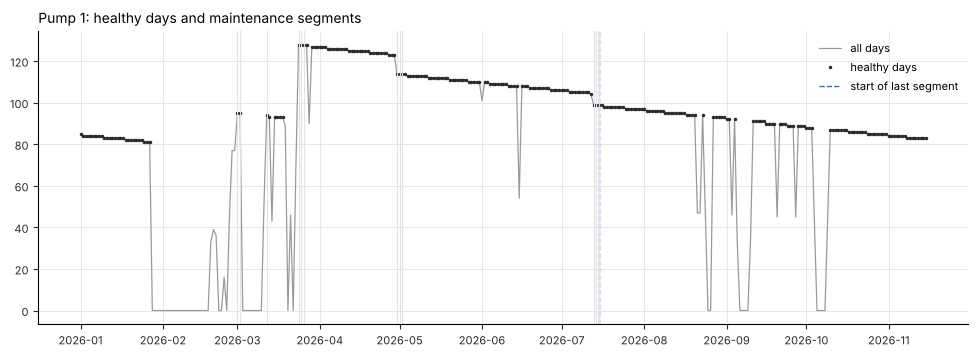

In [5]:
def clean_segments(s, m):
    """Healthy series with glitches removed, plus the start date of every segment."""
    h = s[m]
    vals, idx = list(h.values), list(h.index)
    kept_v, kept_t, starts = [], [], []
    for i, (t, x) in enumerate(zip(idx, vals)):
        if kept_v:
            ref = np.median(kept_v[-5:])
            if abs(x - ref) >= JUMP:
                nxt = vals[i + 1:i + 4]
                persists = sum(abs(y - x) <= 2 for y in nxt) >= min(2, len(nxt))
                if persists:
                    starts.append(t)            # new segment = maintenance / level shift
                else:
                    continue                    # one-off glitch: drop it
        else:
            starts.append(t)
        kept_v.append(x); kept_t.append(t)
    return pd.Series(kept_v, index=kept_t), starts

def trend_slope(seg, t0):
    x = (seg.index - t0).days.values.astype(float)
    return theilslopes(seg.values, x)[0]        # robust (median-of-slopes) line slope

# Example: Pump 1 - raw data, healthy days, and the last segment
s = data["Pump 1"]; m = healthy_mask(s); ser, starts = clean_segments(s, m)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(s.index, s, lw=0.9, color="#9a9a9a", label="all days")
ax.plot(ser.index, ser, ".", ms=3, color=INK, label="healthy days")
ax.axvline(starts[-1], color=ACCENT, lw=1, ls="--", label="start of last segment")
for t in starts[1:]: ax.axvline(t, color=GRID, lw=0.8)
ax.set_title("Pump 1: healthy days and maintenance segments", loc="left", fontsize=10); style(ax)
ax.legend(frameon=False, fontsize=8); plt.show()

## Step 5 - Forecast one equipment

For each equipment:
1. **Offline rule.** If it has no healthy days, or has been offline for the last `OFF_RUN` (7) days in a row, forecast **0%**. In this data, once an outage has lasted 3+ days it carried on the next day about 85-100% of the time, and 7 days gave the best back-test error (Step 7).
2. **Decline slope.** Theil-Sen (robust line) slope over the healthy days of the last segment. If that segment is shorter than 14 days, use the median slope of the equipment's earlier segments instead (or 0 if none). The slope is never allowed to be positive between maintenance events.
3. **Starting level.** The average of the last 3 healthy days of the segment, so the forecast starts from where the equipment actually is now.
4. **Forecast** = starting level + slope x days ahead, never below 0.

The forecast is the *healthy-operation* path: it assumes no new maintenance and no new outage, since neither can be predicted from the dates alone.

In [ ]:
def forecast_one(s, horizon=HORIZON):
    last = s.index[-1]
    fdates = pd.date_range(last + pd.Timedelta(days=1), periods=horizon)
    m = healthy_mask(s)
    run = 0
    for x in s.values[::-1]:
        if x < OFF_LEVEL: run += 1
        else: break
    if (not m.any()) or run >= OFF_RUN:
        return pd.Series(0.0, index=fdates), dict(state="offline", segment_start=None, healthy_days=0, slope_per_day=0.0, start_level=0.0)

    ser, starts = clean_segments(s, m)
    t0 = s.index[0]
    seg = ser[ser.index >= starts[-1]]
    if len(seg) >= MIN_SEG:
        slope = trend_slope(seg, t0)
    else:
        earlier = [ser[(ser.index >= a) & (ser.index < b)] for a, b in zip(starts[:-1], starts[1:])]
        slopes = [trend_slope(e, t0) for e in earlier if len(e) >= MIN_SEG]
        slope = float(np.median(slopes)) if slopes else 0.0
    slope = min(slope, 0.0)

    tail = seg.iloc[-3:]
    anchor_x = ((tail.index - t0).days.values).mean()
    anchor_y = tail.values.mean()
    xf = (fdates - t0).days.values.astype(float)
    pred = np.maximum(anchor_y + slope * (xf - anchor_x), 0.0)
    info = dict(state="online", segment_start=starts[-1].date(), healthy_days=len(seg),
                slope_per_day=round(slope, 4), start_level=round(anchor_y, 1))
    return pd.Series(pred, index=fdates), info

def forecast_all(df, horizon=HORIZON):
    preds, infos = {}, {}
    for c in df.columns:
        preds[c], infos[c] = forecast_one(df[c], horizon)
    return pd.DataFrame(preds), pd.DataFrame(infos).T

# What the model has learned about each equipment from ALL the data
_, model_state = forecast_all(data)
model_state
Y = b + wX

,state,segment_start,healthy_days,slope_per_day,start_level
Pump 1,online,2026-07-15,104,-0.1313,83.0
Pump 2,online,2026-05-02,182,-0.1458,64.0
Pump 3,online,2026-07-17,112,-0.1311,70.0
Pump 4,online,2026-08-03,86,-0.1313,71.0
Pump 5,online,2026-10-15,27,-0.125,83.0
Pump 6,online,2026-07-21,107,-0.1316,83.0
Pump 7,online,2026-07-15,115,-0.1311,83.0
Pump 8,online,2026-07-14,108,-0.1311,83.0
Gen A,offline,None,0,0.0,0.0
Gen B,offline,None,0,0.0,0.0


## Step 6 - Sanity check of the idea on one pump (Pump 3)
Fit on data up to 16 Oct and compare with what really happened afterwards (the full test is Step 8).

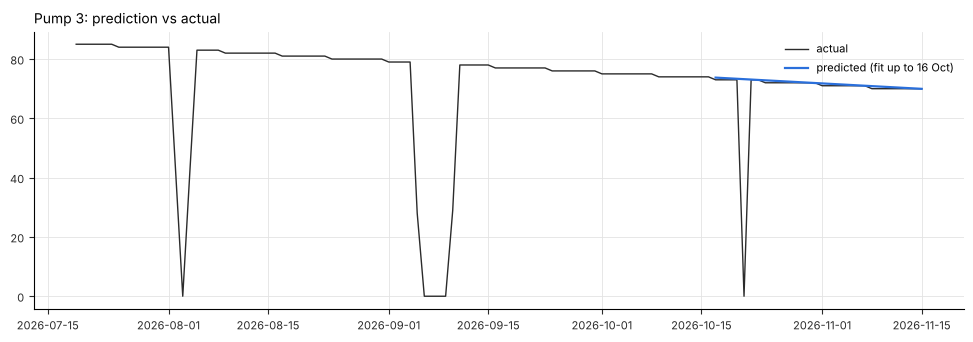

In [7]:
tr = data[data.index <= "2026-10-16"]
f, _ = forecast_one(tr["Pump 3"])
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(data.index[-120:], data["Pump 3"].iloc[-120:], lw=1, color=INK, label="actual")
ax.plot(f.index, f, lw=1.6, color=ACCENT, label="predicted (fit up to 16 Oct)")
ax.set_title("Pump 3: prediction vs actual", loc="left", fontsize=10); style(ax)
ax.legend(frameon=False, fontsize=8); plt.show()

## Step 7 - Back-test on many past periods (choosing and checking the settings)

One test window can be lucky or unlucky, so before trusting the model we repeat the exercise from many starting points: every 5 days from 15 May to 16 Oct 2026 we pretend that is "today", fit on the data up to then, forecast 30 days and compare with reality. We compare against the simplest alternative, **"tomorrow equals the last value"**.

In [8]:
def baseline_last_value(df, horizon=HORIZON):
    idx = pd.date_range(df.index[-1] + pd.Timedelta(days=1), periods=horizon)
    return pd.DataFrame({c: pd.Series(df[c].iloc[-1], index=idx) for c in df.columns})

healthy_all = pd.DataFrame({c: healthy_mask(data[c]) for c in EQUIP})
origins = pd.date_range("2026-05-15", "2026-10-16", freq="5D")
mae_model, mae_base, mae_model_healthy = [], [], []
for o in origins:
    tr = data[data.index <= o]
    te = data[(data.index > o) & (data.index <= o + pd.Timedelta(days=HORIZON))]
    if len(te) < HORIZON: continue
    fm, _ = forecast_all(tr)
    fb = baseline_last_value(tr)
    mae_model.append((te - fm).abs().mean())
    mae_base.append((te - fb).abs().mean())
    mae_model_healthy.append((te - fm).abs().where(healthy_all.loc[te.index]).mean())

bt = pd.DataFrame({
    "Baseline MAE (last value)": pd.concat(mae_base, axis=1).mean(axis=1),
    "Model MAE (all days)": pd.concat(mae_model, axis=1).mean(axis=1),
    "Model MAE (healthy days only)": pd.concat(mae_model_healthy, axis=1).mean(axis=1),
}).round(2)
print(f"{len(mae_model)} back-test origins, 30-day horizon. MAE = mean absolute error in SE percentage points.")
display(bt)
print("Average over equipments:"); print(bt.mean().round(2).to_string())

31 back-test origins, 30-day horizon. MAE = mean absolute error in SE percentage points.
Average over equipments:
Baseline MAE (last value)        14.07
Model MAE (all days)             11.52
Model MAE (healthy days only)     6.28


,Baseline MAE (last value),Model MAE (all days),Model MAE (healthy days only)
Pump 1,16.41,10.04,0.81
Pump 2,9.28,5.04,0.57
Pump 3,12.59,6.00,0.99
Pump 4,23.21,13.44,3.49
Pump 5,28.61,34.53,24.04
Pump 6,23.00,14.33,2.42
Pump 7,24.65,23.12,9.95
Pump 8,11.20,6.67,0.58
Gen A,0.00,0.00,NaN
Gen B,0.00,0.00,NaN


**How to read this:** on average the model roughly halves the healthy-day error of "last value" and is better overall (11.5 vs 14.1 points). It is clearly better for Pump 1-4, 6, 8 and Gen C, about equal for Pump 7, and **worse for Pump 5 and Blackstart**. Those two had long outages that ended unpredictably: when the model sees 7+ days offline it forecasts 0%, which is wrong whenever the equipment comes back inside the next 30 days. The gap between *all days* and *healthy days only* is the error caused by outages that start or end inside the forecast window. Outage timing cannot be predicted from dates, so it is the main limit on accuracy.

## Step 8 - Hold-out test (writes the test CSV)

The **last 30 days of data (17 Oct - 15 Nov 2026) are held out**. The model is fitted only on data up to 16 Oct and then forecasts those 30 days. For each equipment and each test date we record the actual value, the predicted value and the difference (**Difference = Actual - Predicted**).

In [ ]:
train, test = data.iloc[:-TEST_DAYS], data.iloc[-TEST_DAYS:]
print("Training:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} days)")
print("Test    :", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} days)")

pred_test, _ = forecast_all(train, horizon=TEST_DAYS)
assert (pred_test.index == test.index).all()

rows = [] 
        a, p = float(test.at[d_, c]), float(pred_test.at[d_, c])
        rows.append({"Date": d_.strftime("%d/%m/%Y"), "Equipment": c,
                     "Actual_SE_%": a, "Predicted_SE_%": round(p, 2),
                     "Difference_%": round(a - p, 2), "Abs_Difference_%": round(abs(a - p), 2)})
test_results = pd.DataFrame(rows)
test_results.to_csv("SE_test_results.csv", index=False)
print("Saved SE_test_results.csv with", len(test_results), "rows")
test_results.head(50)

Training: 2026-01-01 to 2026-10-16 (289 days)
Test    : 2026-10-17 to 2026-11-15 (30 days)
Saved SE_test_results.csv with 360 rows


,Date,Equipment,Actual_SE_%,Predicted_SE_%,Difference_%,Abs_Difference_%
0,17/10/2026,Pump 1,86.0,86.74,-0.74,0.74
1,18/10/2026,Pump 1,86.0,86.61,-0.61,0.61
2,19/10/2026,Pump 1,86.0,86.48,-0.48,0.48
3,20/10/2026,Pump 1,86.0,86.34,-0.34,0.34
4,21/10/2026,Pump 1,86.0,86.21,-0.21,0.21
5,22/10/2026,Pump 1,86.0,86.08,-0.08,0.08
6,23/10/2026,Pump 1,86.0,85.95,0.05,0.05
7,24/10/2026,Pump 1,85.0,85.82,-0.82,0.82


,MAE (all test days),RMSE,Mean difference (bias),Test days offline,MAE (healthy test days only)
Pump 1,0.38,0.47,-0.37,0,0.38
Pump 2,6.81,18.87,-6.60,2,0.29
Pump 3,2.83,13.38,-2.81,1,0.40
Pump 4,6.32,19.89,-5.95,2,0.29
Pump 5,12.98,31.67,-12.98,4,0.44
Pump 6,3.22,15.60,-3.20,1,0.38
Pump 7,4.66,17.54,-4.65,1,0.40
Pump 8,13.89,32.06,-13.88,4,0.39
Gen A,0.00,0.00,0.00,30,NaN
Gen B,0.00,0.00,0.00,30,NaN


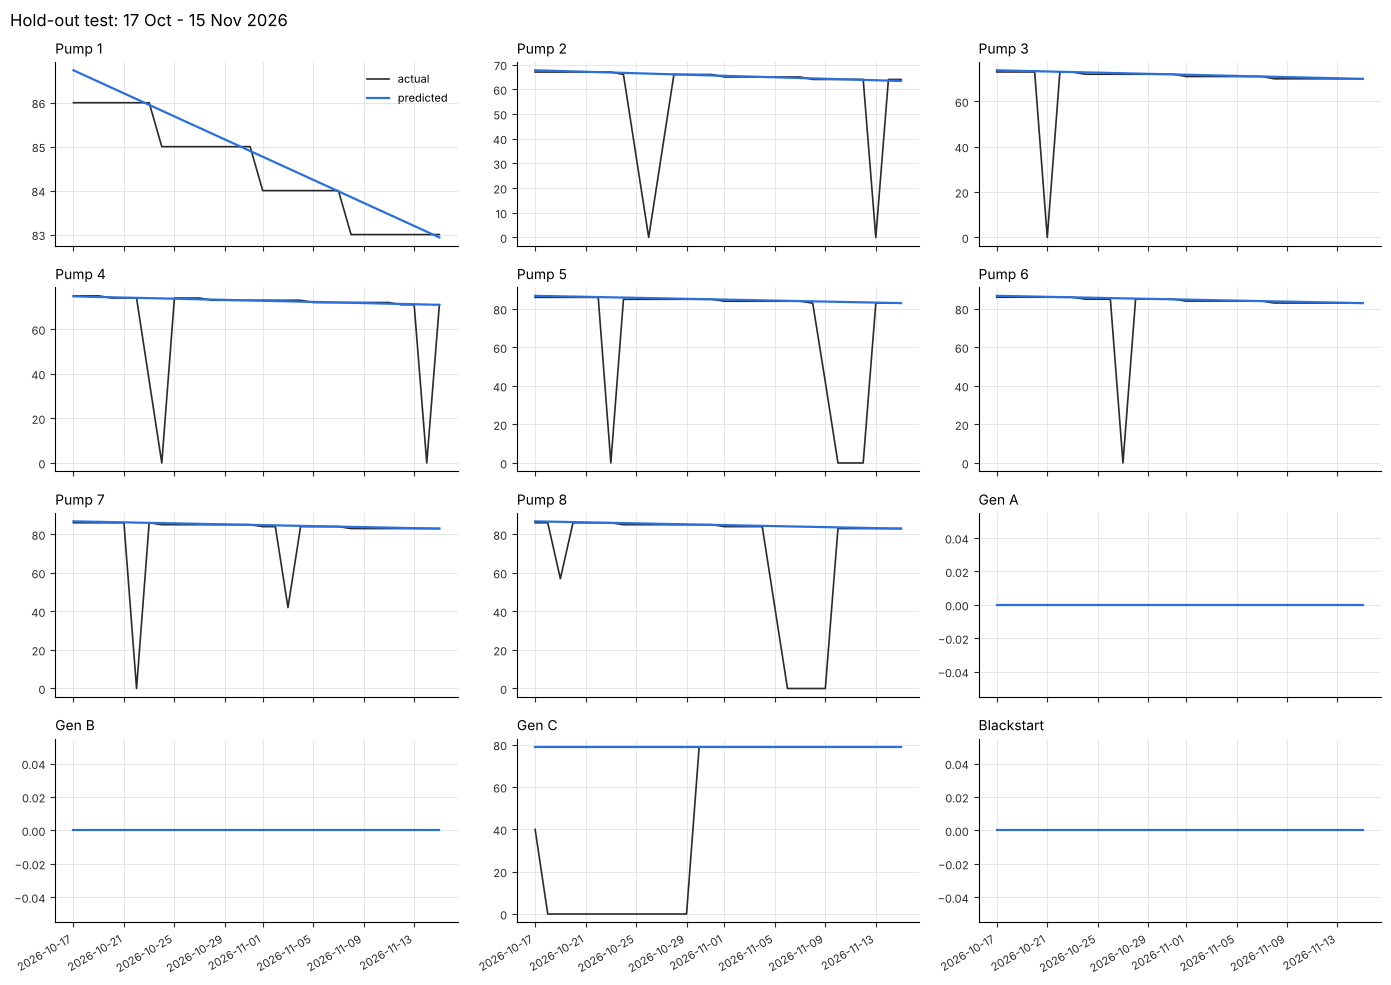

In [10]:
err = test - pred_test
hm = healthy_all.loc[test.index]
metrics = pd.DataFrame({
    "MAE (all test days)": err.abs().mean(),
    "RMSE": np.sqrt((err ** 2).mean()),
    "Mean difference (bias)": err.mean(),
    "Test days offline": (test < OFF_LEVEL).sum(),
    "MAE (healthy test days only)": err.abs().where(hm).mean(),
}).round(2)
display(metrics)

fig, axes = plt.subplots(4, 3, figsize=(14, 10), sharex=True)
for ax, c in zip(axes.ravel(), EQUIP):
    ax.plot(test.index, test[c], lw=1.2, color=INK, label="actual")
    ax.plot(pred_test.index, pred_test[c], lw=1.6, color=ACCENT, label="predicted")
    ax.set_title(c, fontsize=10, loc="left"); style(ax)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Hold-out test: 17 Oct - 15 Nov 2026", x=0.01, ha="left", fontsize=12)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

**Reading the test:** on days when the equipment was actually running, errors are small (see the healthy-days column). The large errors come from outages inside the window that no date-based model can foresee: Gen C went offline 17-29 Oct, Pump 8 and Pump 5 each had short outages in November, and so on. Gen A, Gen B and Blackstart (0% throughout) are predicted exactly.

## Step 9 - Final 30-day forecast (writes the forecast CSV)

Now the model is refitted on **all** the data (1 Jan - 15 Nov 2026) and forecasts 16 Nov 2026 to 15 Dec 2026.

In [11]:
forecast, final_state = forecast_all(data, horizon=HORIZON)
assert forecast.index[0] == pd.Timestamp("2026-11-16") and len(forecast) == 30

out = forecast.round(2).copy()
out.insert(0, "Date", out.index.strftime("%d/%m/%Y"))
out.to_csv("SE_forecast_30_days.csv", index=False)
print("Saved SE_forecast_30_days.csv:", forecast.index[0].date(), "to", forecast.index[-1].date())
out.reset_index(drop=True).iloc[[0, 1, 2, 14, 28, 29]]

Saved SE_forecast_30_days.csv: 2026-11-16 to 2026-12-15


,Date,Pump 1,Pump 2,Pump 3,Pump 4,Pump 5,Pump 6,Pump 7,Pump 8,Gen A,Gen B,Gen C,Blackstart
0,16/11/2026,82.74,63.66,69.74,70.65,82.75,82.74,82.74,82.74,0.0,0.0,78.99,0.0
1,17/11/2026,82.61,63.51,69.61,70.52,82.62,82.61,82.61,82.61,0.0,0.0,78.99,0.0
2,18/11/2026,82.47,63.37,69.48,70.39,82.50,82.47,82.48,82.48,0.0,0.0,78.98,0.0
14,30/11/2026,80.90,61.62,67.90,68.81,81.00,80.89,80.90,80.90,0.0,0.0,78.94,0.0
28,14/12/2026,79.06,59.58,66.07,66.97,79.25,79.05,79.07,79.07,0.0,0.0,78.88,0.0
29,15/12/2026,78.93,59.43,65.93,66.84,79.12,78.92,78.93,78.93,0.0,0.0,78.88,0.0


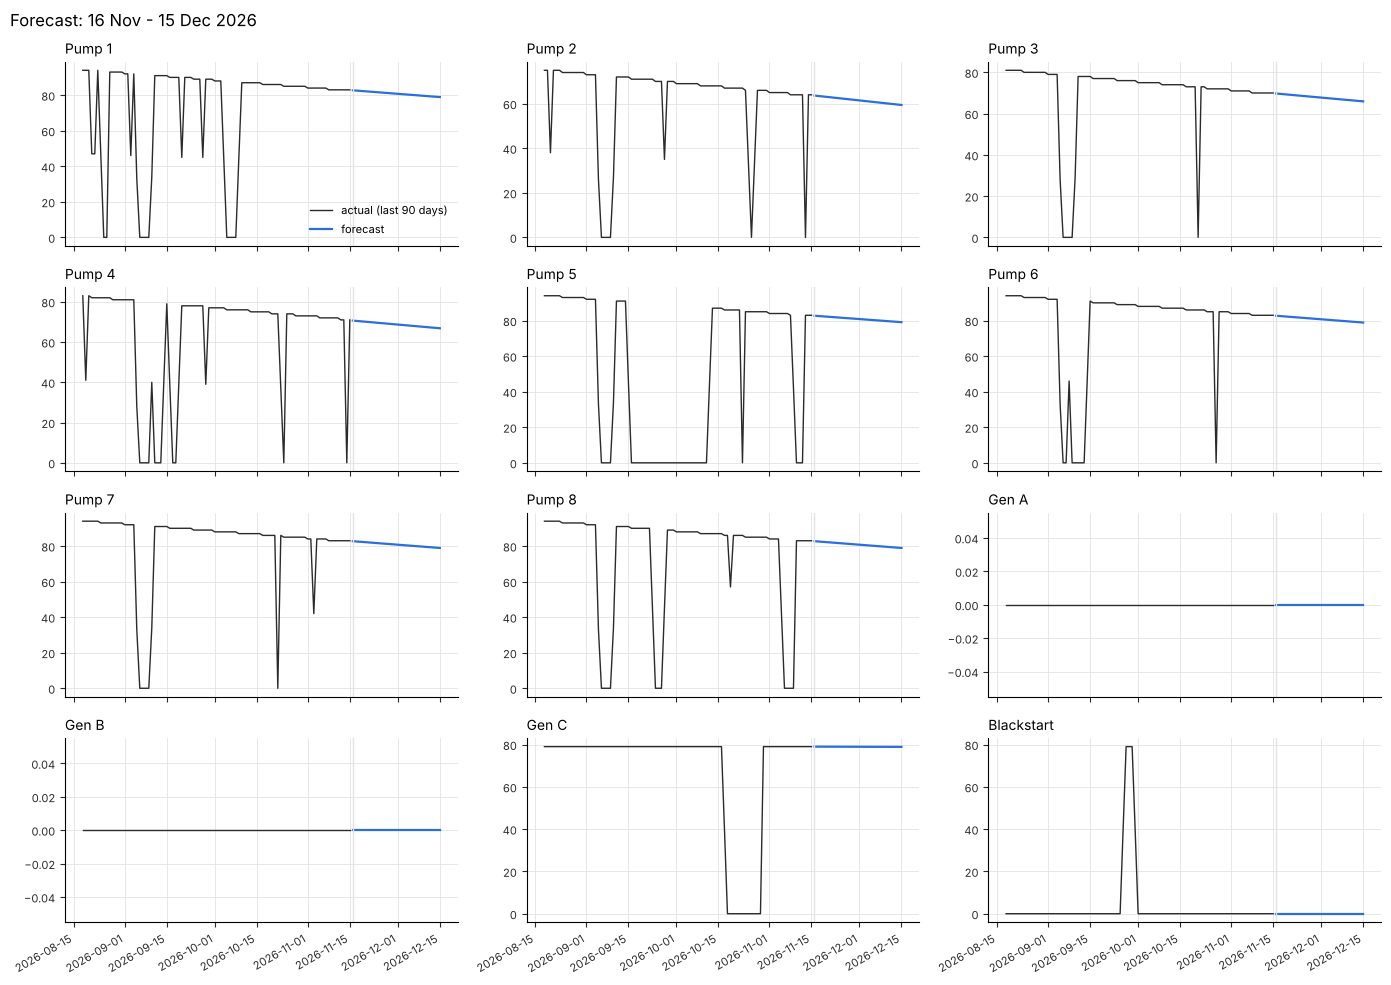

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(14, 10), sharex=True)
hist = data.iloc[-90:]
for ax, c in zip(axes.ravel(), EQUIP):
    ax.plot(hist.index, hist[c], lw=1, color=INK, label="actual (last 90 days)")
    ax.plot(forecast.index, forecast[c], lw=1.6, color=ACCENT, label="forecast")
    ax.axvline(pd.Timestamp("2026-11-16"), color=GRID, lw=1)
    ax.set_title(c, fontsize=10, loc="left"); style(ax)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Forecast: 16 Nov - 15 Dec 2026", x=0.01, ha="left", fontsize=12)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## Assumptions and limits
- **No new maintenance is assumed.** A maintenance event lifts SE (sometimes above 100%), but the data has only three or four such events, at irregular intervals, so their timing cannot be forecast. If maintenance happens in the next 30 days, the real values will be above this forecast from that date.
- **No new outage is assumed** for equipment that is currently running, and an equipment that has been offline for 7+ days is assumed to stay at 0%. Real outages (and returns from outage) will show up as large differences, as in the test results.
- Forecast values are the expected *healthy-operation* level, in percentage points, and the further out the date the less certain the value.
- Settings (`OFF_LEVEL`, `DROP_FRAC`, `JUMP`, `MIN_SEG`, `OFF_RUN`) are in Step 1; the back-test in Step 7 can be re-run after changing them.
- Output files: `SE_test_results.csv` (Step 8, long format: one row per equipment per test date) and `SE_forecast_30_days.csv` (Step 9, one row per date, one column per equipment).